In [5]:
# ==========================================
# CELL 1: IMPORT LIBRARIES AND LOAD DATASET
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Load dataset
df = pd.read_csv("../data/telecom_customer_churn.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 38)


,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,9,NaN,Yes,42.39,No,Yes,Cable,16.0,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,9,NaN,Yes,10.69,Yes,Yes,Cable,10.0,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.0,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,3,NaN,Yes,7.38,No,Yes,Fiber Optic,11.0,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


Target column: Customer Status

Customer Status Counts:


Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


Customer Status Percentages:


Customer Status
Stayed     67.02
Churned    26.54
Joined      6.45
Name: proportion, dtype: float64

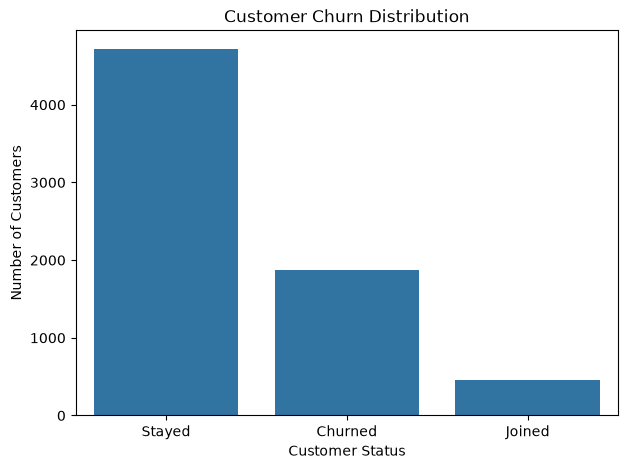

In [6]:
# ==========================================
# CELL 2: TARGET VARIABLE ANALYSIS
# ==========================================

print("Target column: Customer Status")

print("\nCustomer Status Counts:")
display(df["Customer Status"].value_counts())

print("\nCustomer Status Percentages:")
display(
    (df["Customer Status"].value_counts(normalize=True) * 100)
    .round(2)
)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Customer Status"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
# ==========================================
# CELL 3: CATEGORICAL FEATURE INSPECTION
# ==========================================

categorical_columns = df.select_dtypes(include=["object", "str"]).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).head(15))


--- Customer ID ---
Customer ID
0002-ORFBO    1
0003-MKNFE    1
0004-TLHLJ    1
0011-IGKFF    1
0013-EXCHZ    1
0013-MHZWF    1
0013-SMEOE    1
0014-BMAQU    1
0015-UOCOJ    1
0016-QLJIS    1
0017-DINOC    1
0017-IUDMW    1
0018-NYROU    1
0019-EFAEP    1
0019-GFNTW    1
Name: count, dtype: int64

--- Gender ---
Gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Married ---
Married
No     3641
Yes    3402
Name: count, dtype: int64

--- City ---
City
Los Angeles      293
San Diego        285
San Jose         112
Sacramento       108
San Francisco    104
Fresno            61
Long Beach        60
Oakland           52
Escondido         51
Stockton          44
Fallbrook         43
Glendale          40
Bakersfield       39
Temecula          38
Berkeley          32
Name: count, dtype: int64

--- Offer ---
Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

--- Phone Service ---
Phone Service
Yes    

Customer Status vs Tenure


,count,min,max,mean,median
Customer Status,,,,,
Churned,1869,1,72,17.98,10.0
Joined,454,1,3,1.72,1.0
Stayed,4720,4,72,41.04,42.0


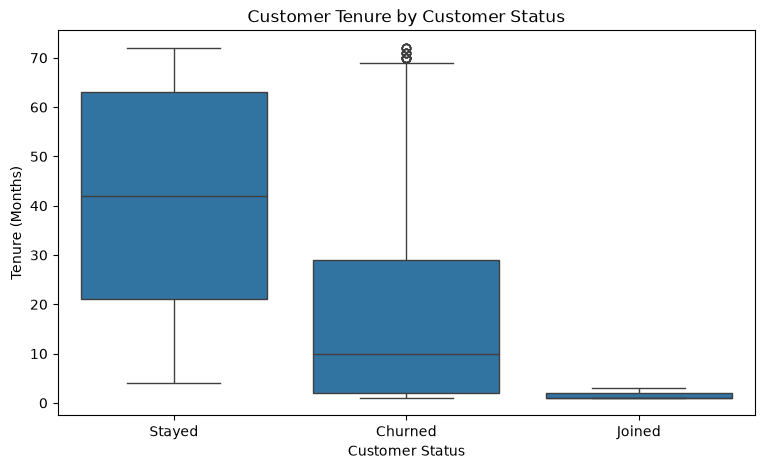

In [8]:
# ==========================================
# CELL 4: CUSTOMER STATUS AND TENURE ANALYSIS
# ==========================================

print("Customer Status vs Tenure")

display(df.groupby("Customer Status") ["Tenure in Months"]   .agg(["count", "min", "max", "mean", "median"])    .   round(2))

# Visualize tenure distribution by customer status

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Customer Status",
    y="Tenure in Months"
)

plt.title("Customer Tenure by Customer Status")
plt.xlabel("Customer Status")
plt.ylabel("Tenure (Months)")

plt.show()

NUMERICAL FEATURE SUMMARY


Age                Number of Dependents                 \
                  mean median min max                 mean median min max   
Customer Status                                                             
Churned          49.74   50.0  19  80                 0.12    0.0   0   7   
Stayed           45.58   45.0  19  80                 0.62    0.0   0   9   

                Number of Referrals                Tenure in Months         \
                               mean median min max             mean median   
Customer Status                                                              
Churned                        0.52    0.0   0   9            17.98   10.0   
Stayed                         2.61    1.0   0  11            41.04   42.0   

                        Avg Monthly Long Distance Charges                      \
                min max                              mean median   min    max   
Customer Status                                                                 
Churned           1  72                             25.49  25.77  1.02  49.98   
Stayed            4  72                             25.50  25.69  1.01  49.99   

                Avg Monthly GB Download                   Monthly Charge  \
                                   mean median  min   max           mean   
Customer Status                                                            
Churned                           23.60   20.0  2.0  85.0          73.35   
Stayed                            27.55   22.0  2.0  85.0          61.74   

                                     Total Charges                           
                median   min     max          mean   median    min      max  
Customer Status                                                              
Churned           79.5 -10.0  118.35       1531.80   703.55  18.85  8684.80  
Stayed            65.6 -10.0  118.75       2788.52  1940.82  55.70  8672.45

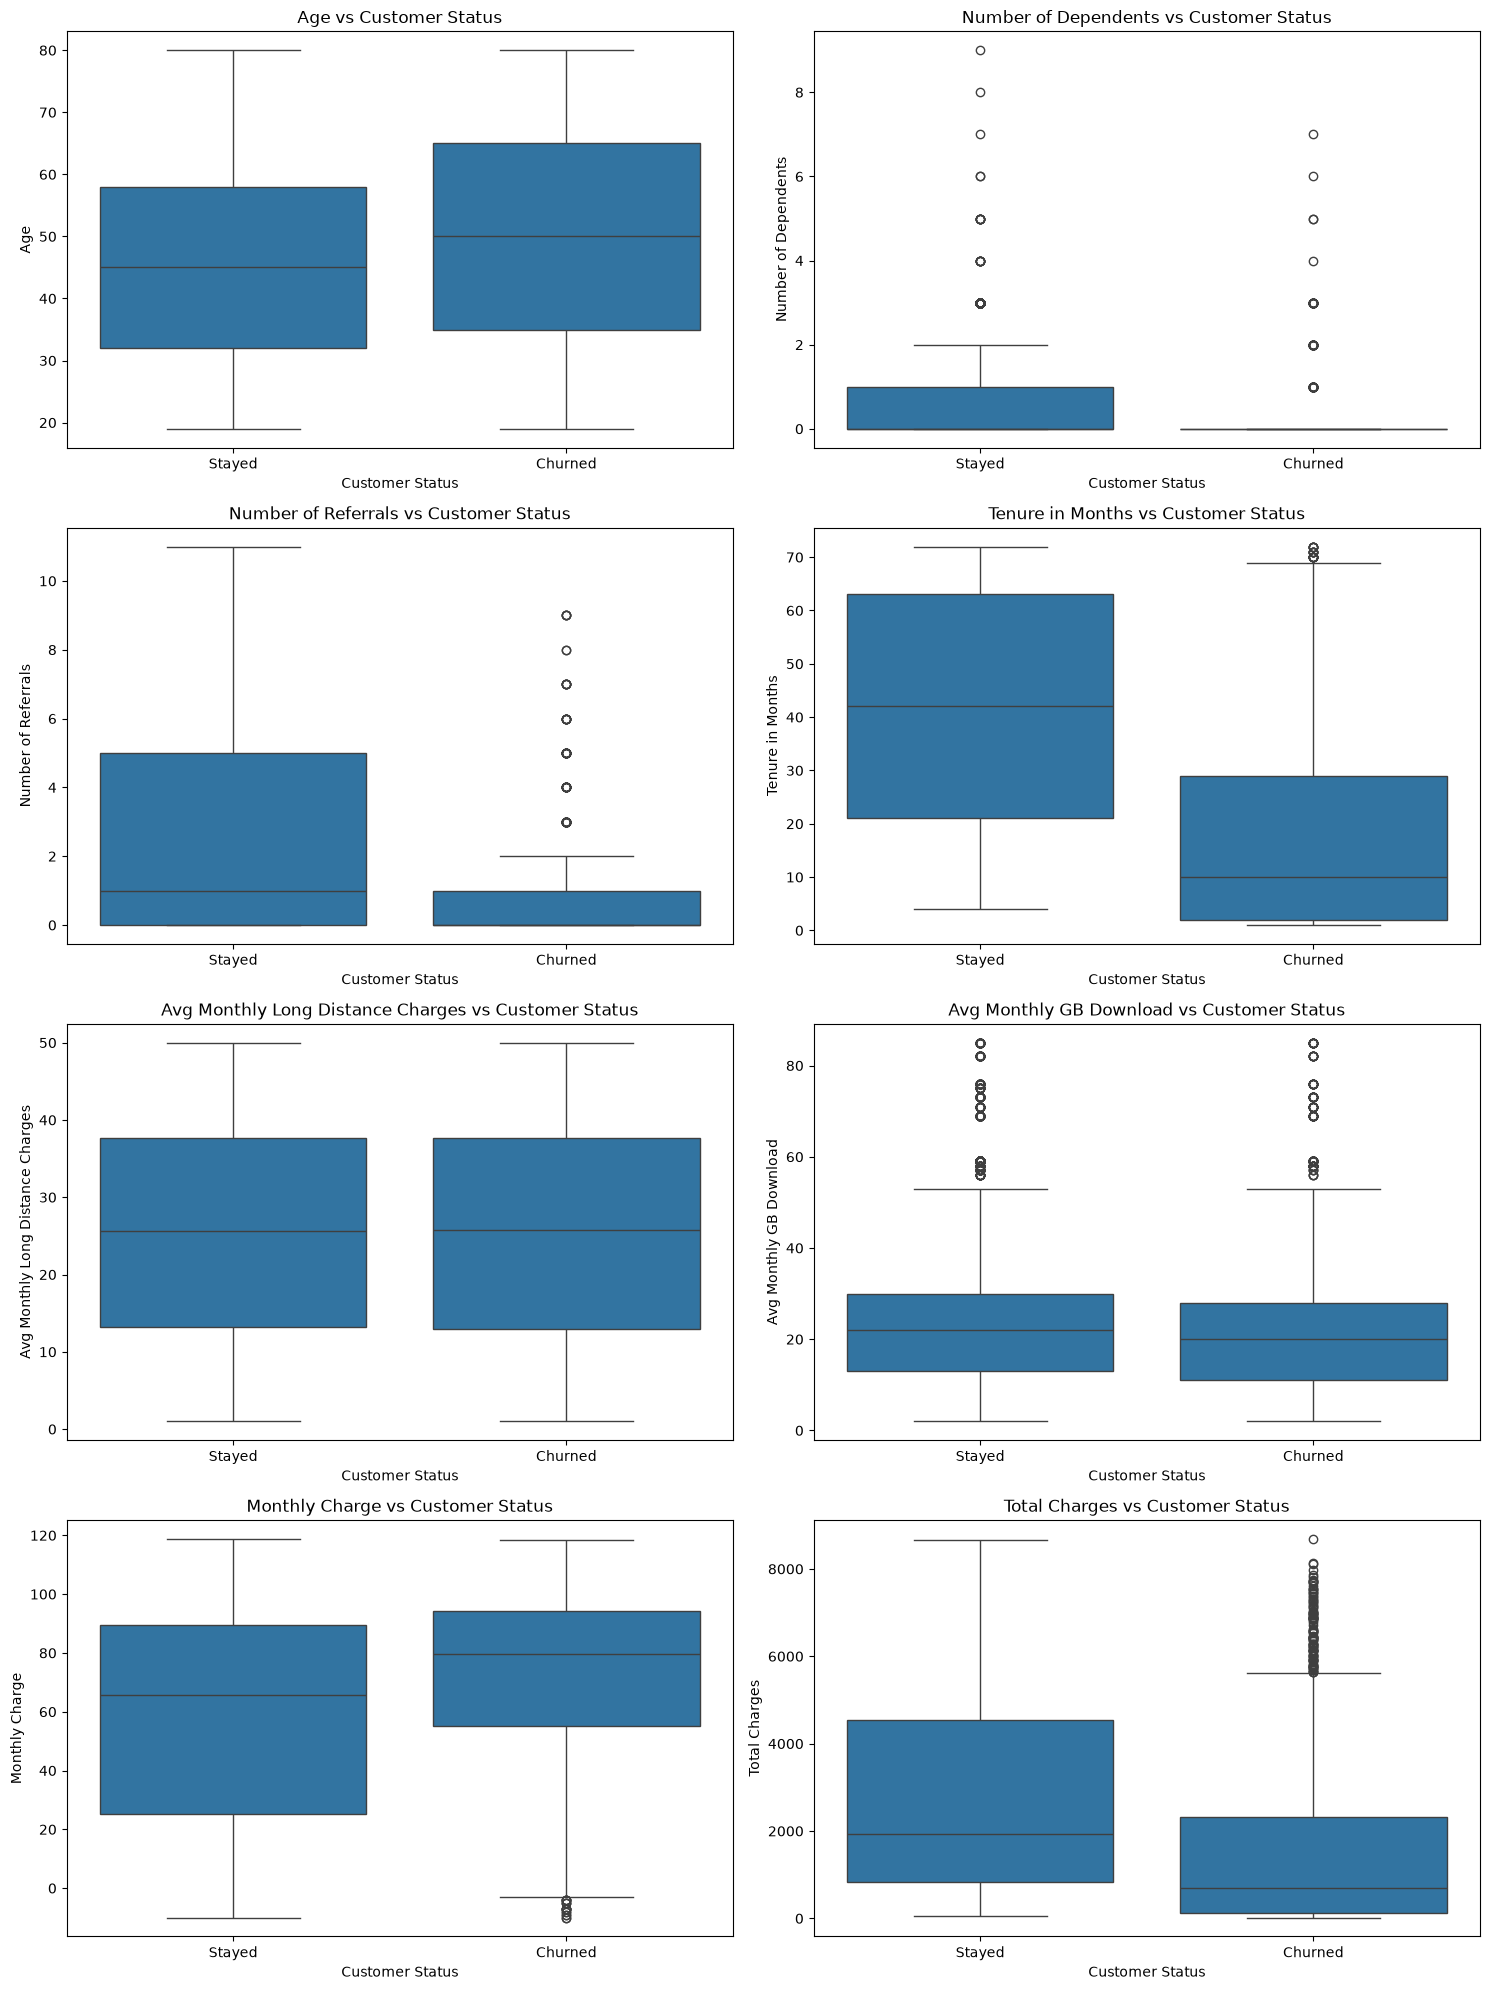

In [9]:

# ==========================================
# CELL 5: NUMERICAL FEATURE ANALYSIS
# ==========================================

# Keep only existing customers with a known outcome
# Without been modifying the original df

eda_df = df[df["Customer Status"].isin(
    ["Stayed", "Churned"]
)].copy()

# Numerical features to investigate
numeric_features = [ "Age",    "Number of Dependents",
    "Number of Referrals",
    "Tenure in Months",
    "Avg Monthly Long Distance Charges",
    "Avg Monthly GB Download",
    "Monthly Charge",
    "Total Charges"
]

# Summary statistics by customer status
print("NUMERICAL FEATURE SUMMARY")

display(
    eda_df.groupby("Customer Status")[numeric_features]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

# Visual comparison
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

for feature, ax in zip(numeric_features, axes.flatten()):

    sns.boxplot(
        data=eda_df,
        x="Customer Status",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Customer Status")
    ax.set_xlabel("Customer Status")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()



========== Gender ==========


,Customers,Churn_Rate
Gender,,
Female,3277,28.65
Male,3312,28.08



========== Married ==========


,Customers,Churn_Rate
Married,,
No,3271,36.69
Yes,3318,20.16



========== Phone Service ==========


,Customers,Churn_Rate
Phone Service,,
Yes,5945,28.58
No,644,26.40


... (18 outputs left out)


========== Payment Method ==========


,Customers,Churn_Rate
Payment Method,,
Mailed Check,343,41.40
Bank Withdrawal,3728,35.65
Credit Card,2518,15.81



========== Offer ==========


,Customers,Churn_Rate
Offer,,
Offer E,630,67.62
Not Applicable,3598,29.21
Offer D,602,26.74
Offer C,415,22.89
Offer B,824,12.26
Offer A,520,6.73


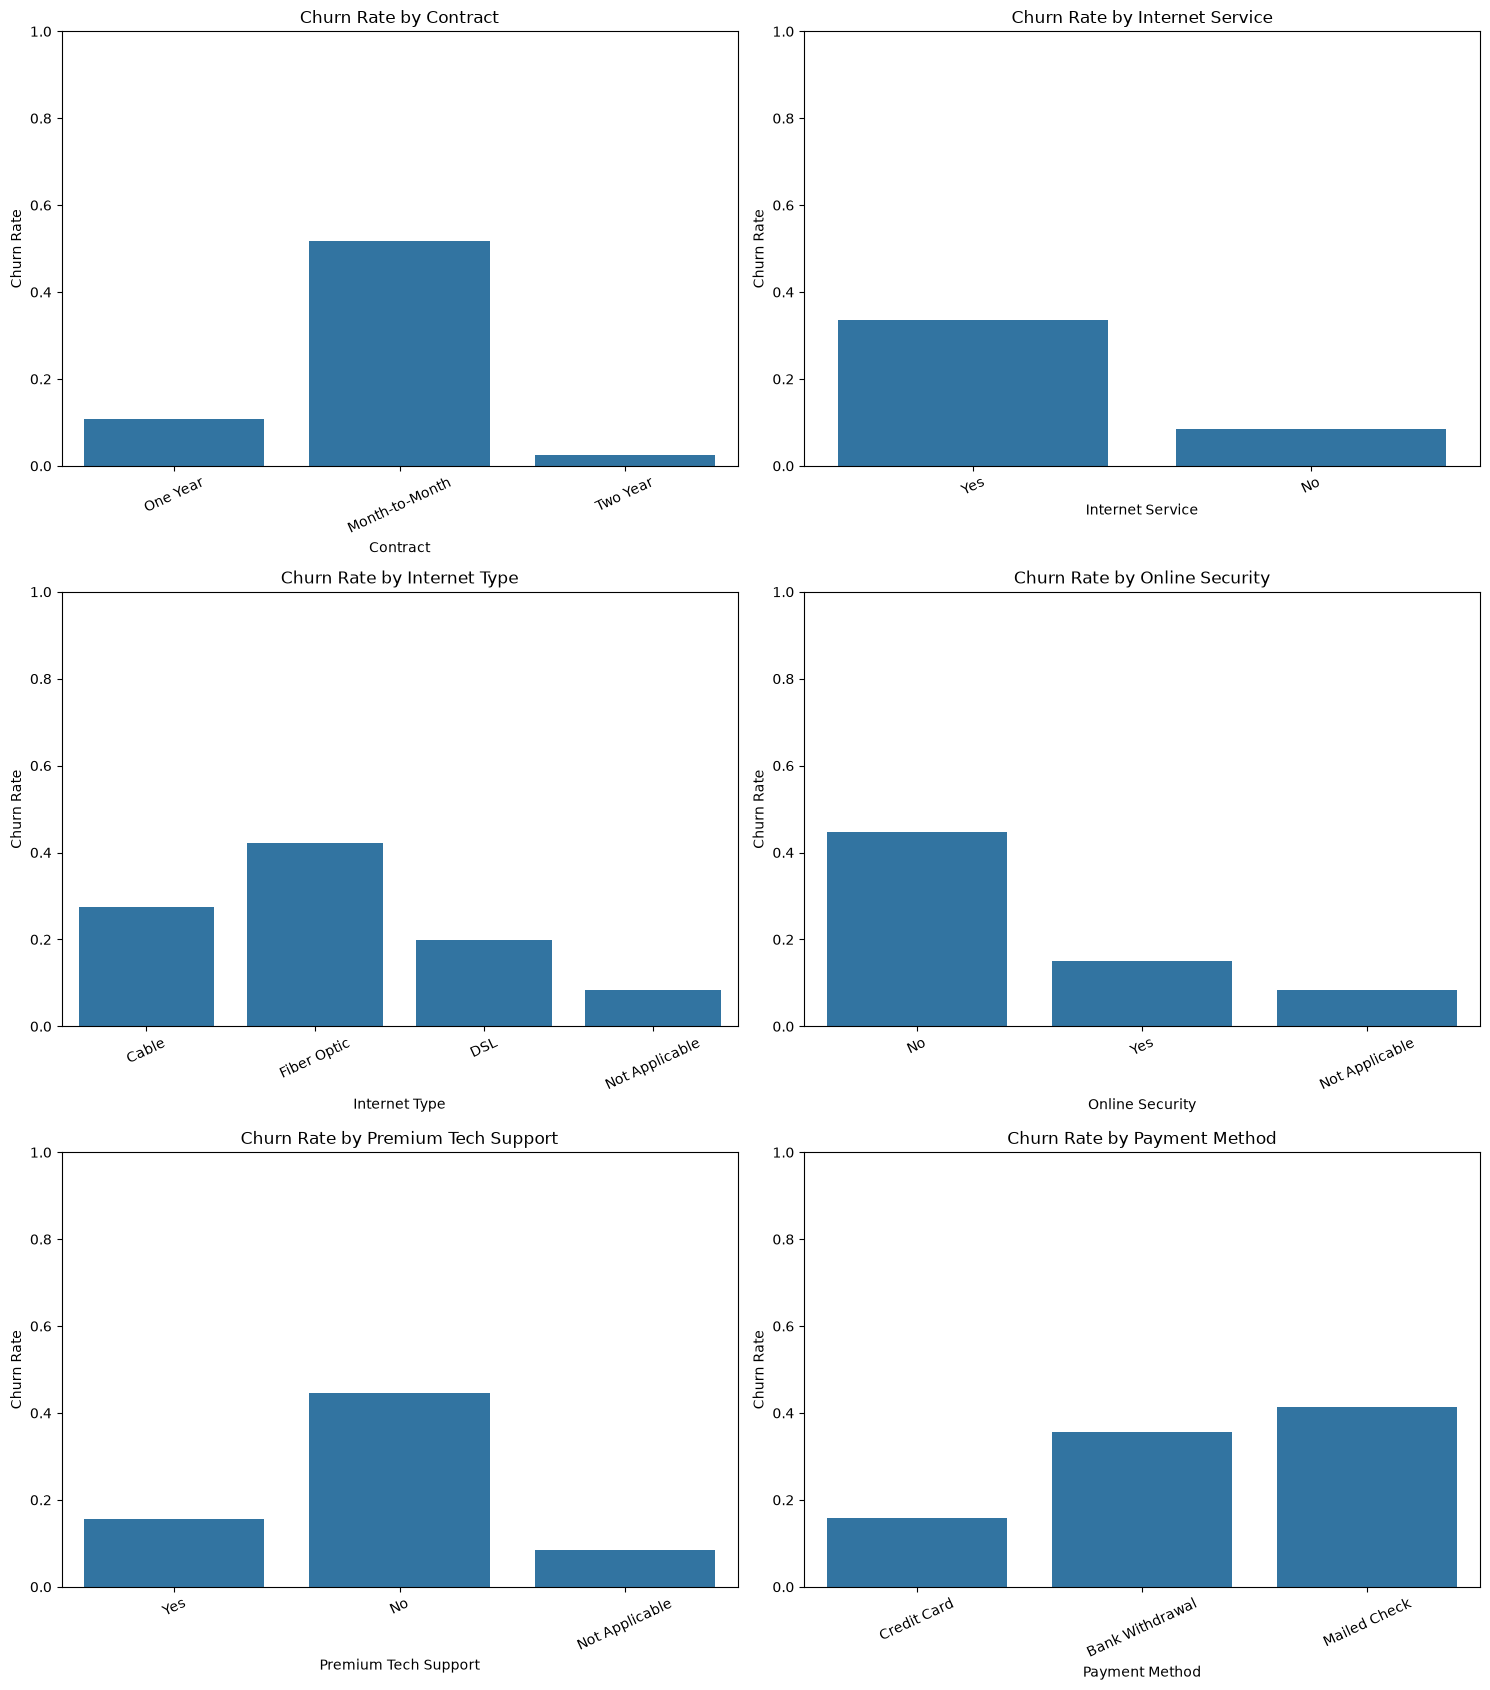

In [10]:

# ==========================================
# CELL 6: CATEGORICAL FEATURE ANALYSIS
# ==========================================

# Categorical features to investigate
categorical_features = [
    "Gender",
    "Married",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Internet Type",
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Offer"
]

# Create a copy and handle missing categories for EDA
cat_eda = eda_df.copy()

for feature in categorical_features:
    cat_eda[feature] = cat_eda[feature].fillna("Not Applicable")

# Convert target into a binary indicator for calculating churn rate
cat_eda["Churn Flag"] = (
    cat_eda["Customer Status"] == "Churned"
).astype(int)

# Calculate customer count and churn rate
for feature in categorical_features:

    print(f"\n========== {feature} ==========")

    summary = (
        cat_eda.groupby(feature, observed=True)
        .agg(
            Customers=("Churn Flag", "count"),
            Churn_Rate=("Churn Flag", "mean")
        )
        .sort_values("Churn_Rate", ascending=False)
    )

    summary["Churn_Rate"] = (
        summary["Churn_Rate"] * 100
    ).round(2)

    display(summary)

# Visualize selected categorical features
plot_features = [
    "Contract",
    "Internet Service",
    "Internet Type",
    "Online Security",
    "Premium Tech Support",
    "Payment Method"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

for feature, ax in zip(plot_features, axes.flatten()):

    sns.barplot(
        data=cat_eda,
        x=feature,
        y="Churn Flag",
        estimator="mean",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_ylabel("Churn Rate")
    ax.set_xlabel(feature)
    ax.set_ylim(0, 1)

    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


Correlation with Churn:


,Correlation
Monthly Charge,0.168
Age,0.111
Avg Monthly Long Distance Charges,-0.000
Avg Monthly GB Download,-0.095
Number of Dependents,-0.233
Number of Referrals,-0.312
Tenure in Months,-0.434


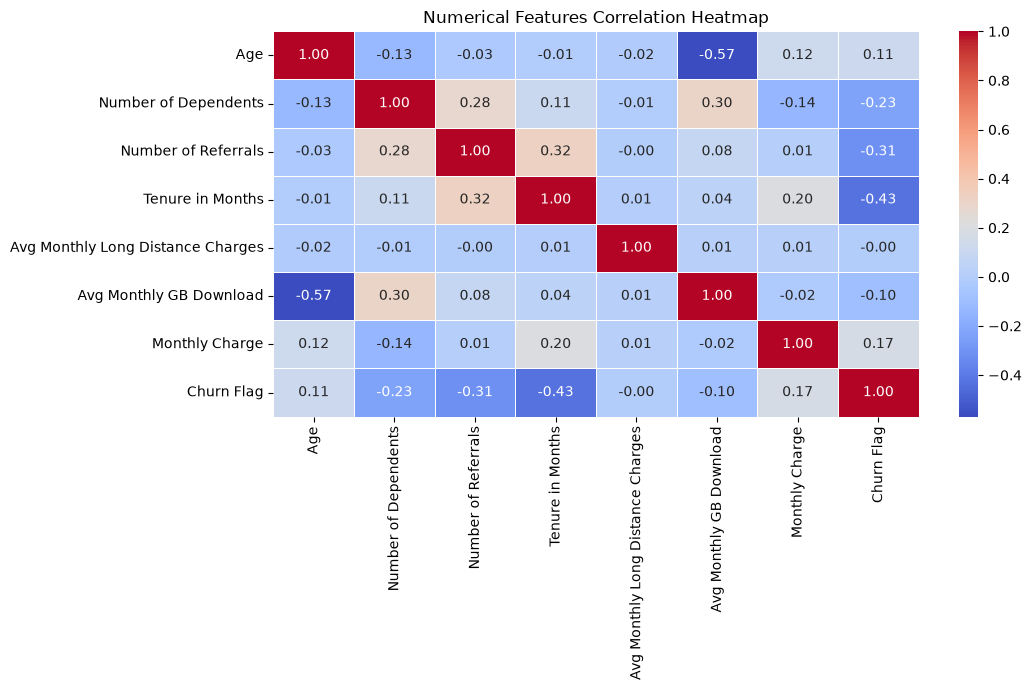

In [11]:

# ==========================================
# CELL 7: NUMERICAL CORRELATION ANALYSIS
# ==========================================

# Work only with customers who stayed or churned
corr_df = eda_df.copy()

# Convert target into binary values
corr_df["Churn Flag"] = (
    corr_df["Customer Status"] == "Churned"
).astype(int)

# Select numerical features for analysis
correlation_features = [
    "Age",
    "Number of Dependents",
    "Number of Referrals",
    "Tenure in Months",
    "Avg Monthly Long Distance Charges",
    "Avg Monthly GB Download",
    "Monthly Charge",
    "Churn Flag"
]

# Calculate correlations
correlation_matrix = corr_df[
    correlation_features
].corr(numeric_only=True)

print("Correlation with Churn:")

display(
    correlation_matrix["Churn Flag"]
    .drop("Churn Flag")
    .sort_values(ascending=False)
    .to_frame("Correlation")
    .round(3)
)

# Draw heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()


In [12]:

# ==========================================
# CELL 8: MISSING VALUE ANALYSIS
# ==========================================

# Proposed 15 input features
candidate_features = [
    "Age",
    "Married",
    "Number of Dependents",
    "Number of Referrals",
    "Tenure in Months",
    "Internet Service",
    "Internet Type",
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support",
    "Contract",
    "Paperless Billing",
    "Payment Method",
    "Monthly Charge"
]

# Analyze missing values
missing_summary = pd.DataFrame({
    "Missing Count": eda_df[candidate_features].isnull().sum(),
    "Missing Percentage": (
        eda_df[candidate_features].isnull().mean() * 100
    ).round(2),
    "Data Type": eda_df[candidate_features].dtypes.astype(str)
})

print("MISSING VALUE SUMMARY")

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

# Inspect unique values in categorical features
print("\n========== CATEGORY VALUES ==========")

for feature in candidate_features:
    if eda_df[feature].dtype == "object":
        print(f"\n{feature}")
        print(
            eda_df[feature]
            .value_counts(dropna=False)
            .to_dict()
        )

# Check target labels
print("\n========== TARGET CHECK ==========")
print(eda_df["Customer Status"].value_counts())


MISSING VALUE SUMMARY


,Missing Count,Missing Percentage,Data Type
Internet Type,1344,20.4,str
Online Backup,1344,20.4,str
Online Security,1344,20.4,str
Premium Tech Support,1344,20.4,str
Device Protection Plan,1344,20.4,str
Married,0,0.0,str
Age,0,0.0,int64
Internet Service,0,0.0,str
Tenure in Months,0,0.0,int64
Number of Referrals,0,0.0,int64



========== CATEGORY VALUES ==========

========== TARGET CHECK ==========
Customer Status
Stayed     4720
Churned    1869
Name: count, dtype: int64


In [13]:

# ==========================================
# CELL 9: VERIFY INTERNET-RELATED MISSING VALUES
# ==========================================

internet_features = [
    "Internet Service",
    "Internet Type",
    "Online Backup",
    "Online Security",
    "Premium Tech Support",
    "Device Protection Plan"
]

# Check Internet Service distribution
print("INTERNET SERVICE DISTRIBUTION")

display(
    eda_df["Internet Service"].value_counts(dropna=False)
)

# Check whether missing values correspond to no internet
print("\nMISSING VALUES BY INTERNET SERVICE")

for feature in internet_features[1:]:

    print(f"\n========== {feature} ==========")

    display(
        pd.crosstab(
            eda_df["Internet Service"],
            eda_df[feature].isna(),
            margins=True
        )
    )

# Check exact categories
print("\n========== UNIQUE VALUES ==========")

for feature in internet_features:

    print(f"\n{feature}:")
    print(eda_df[feature].value_counts(dropna=False))


INTERNET SERVICE DISTRIBUTION


Internet Service
Yes    5245
No     1344
Name: count, dtype: int64


MISSING VALUES BY INTERNET SERVICE

========== Internet Type ==========


Internet Type,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Online Backup ==========


Online Backup,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589


... (3 outputs left out)

Premium Tech Support,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Device Protection Plan ==========


Device Protection Plan,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== UNIQUE VALUES ==========

Internet Service:
Internet Service
Yes    5245
No     1344
Name: count, dtype: int64

Internet Type:
Internet Type
Fiber Optic    2934
DSL            1537
NaN            1344
Cable           774
Name: count, dtype: int64

Online Backup:
Online Backup
No     2870
Yes    2375
NaN    1344
Name: count, dtype: int64

Online Security:
Online Security
No     3272
Yes    1973
NaN    1344
Name: count, dtype: int64

Premium Tech Support:
Premium Tech Support
No     3248
Yes    1997
NaN    1344
Name: count, dtype: int64

Device Protection Plan:
Device Protection Plan
No     2855
Yes    2390
NaN    1344
Name: count, dtype: int64


In [15]:

# ==========================================
# CELL 9: VERIFY STRUCTURAL MISSING VALUES
# ==========================================

internet_features = [
    "Internet Type",
    "Online Backup",
    "Online Security",
    "Premium Tech Support",
    "Device Protection Plan"
]

for feature in internet_features:

    print(f"\n========== {feature} ==========")

    display(
        pd.crosstab(
            eda_df["Internet Service"],
            eda_df[feature].isna(),
            margins=True
        )
    )



========== Internet Type ==========


Internet Type,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Online Backup ==========


Online Backup,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Online Security ==========


Online Security,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Premium Tech Support ==========


Premium Tech Support,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589



========== Device Protection Plan ==========


Device Protection Plan,False,True,All
Internet Service,,,
No,0,1344,1344
Yes,5245,0,5245
All,5245,1344,6589
